# Đánh giá và phân tích lỗi
Dùng số đo thật, kiểm tra nhãn, MAE/RMSE, khoảng dự báo và cảnh báo hiếm. Các origin cách nhau 10 phút có cửa sổ nhãn một giờ chồng lấp.

## Thiết lập
Nạp thư viện và cùng các hàm xử lý được sử dụng trong mã nguồn.

In [1]:
from pathlib import Path
import sys, json

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/appliances").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.appliances.config import RELEASE, MODEL_DIR, HORIZONS, BOUNDARIES
from src.appliances.data import load_data
from src.appliances.features import supervised, split_rows, make_features, feature_columns

raw, audit = load_data()
rows, columns = supervised(raw)
parts, counts = split_rows(rows)


def read_json(name):
    return json.loads((RELEASE / name).read_text(encoding="utf-8"))


## 4.1 Sai số điểm, khoảng dự báo và cảnh báo
Đọc MAE/RMSE theo tập và theo khoảng dự báo, cùng các chỉ số cảnh báo.

In [2]:
metrics = read_json("metrics.json")
display(pd.DataFrame({s: m["point"] for s, m in metrics.items()}).T.drop(columns="horizons"))
display(pd.DataFrame(metrics["test"]["point"]["horizons"]))
display(pd.Series(metrics["test"]["interval"]))
display(pd.Series(metrics["test"]["alert"]))


,rows,mae_step_kWh,rmse_step_kWh,mae_hour_kWh,rmse_hour_kWh,bias_hour_kWh,high_rows,high_mae_hour_kWh
train,11988,0.034301,0.084061,0.168361,0.362481,-0.102204,600,1.176801
validation,2010,0.034664,0.08418,0.167801,0.355399,-0.079768,104,1.135949
calibration,2010,0.03057,0.073501,0.151863,0.311546,-0.059186,53,1.243383
test,2695,0.030932,0.074972,0.150373,0.318112,-0.067265,117,1.125947


,minutes,mae_kWh,rmse_kWh
0,10,0.022919,0.059130
1,20,0.028495,0.075195
2,30,0.031362,0.076843
3,40,0.032471,0.078352
4,50,0.034378,0.079555
5,60,0.035968,0.080759


coverage                                                     0.784787
width_kWh                                                    0.545817
high_coverage                                                0.512821
pinball             {'0.1': 0.028403092579176767, '0.5': 0.0874252...
nominal_coverage                                                  0.8
guaranteed                                                      False
dtype: object

tp                                                                     90
fp                                                                    317
fn                                                                     27
tn                                                                   2261
precision                                                         0.22113
recall                                                           0.769231
f1                                                               0.343511
false_positive_rate                                              0.122964
false_discovery_rate                                              0.77887
positive_prevalence                                              0.043414
average_precision                                                0.363065
pr_auc_trapezoid                                                 0.356232
roc_auc_ranking                                                   0.92565
definition              Overlapping fo

## 4.2 Biểu đồ kết quả trên TEST
Đối chiếu số đo, khoảng dự báo, sai số theo chân trời và precision–recall.

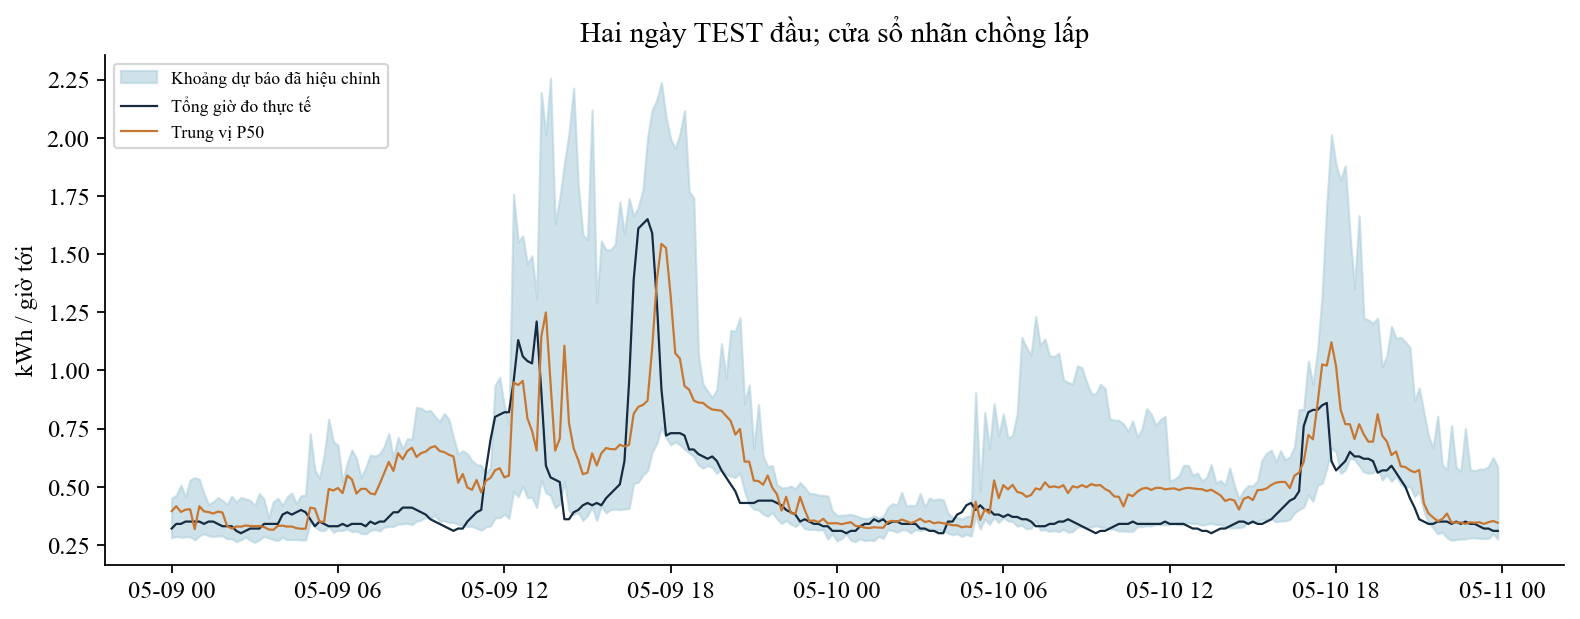

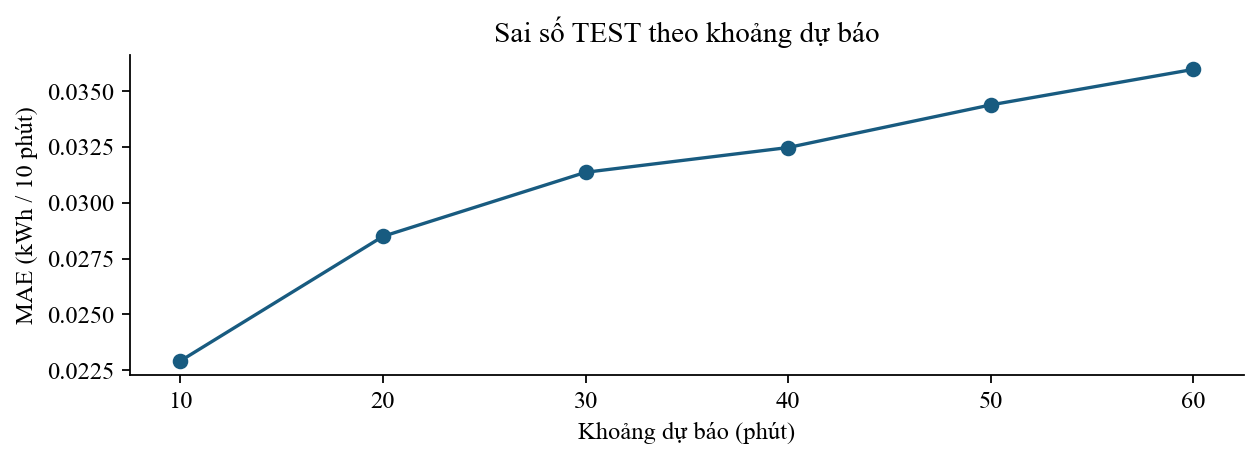

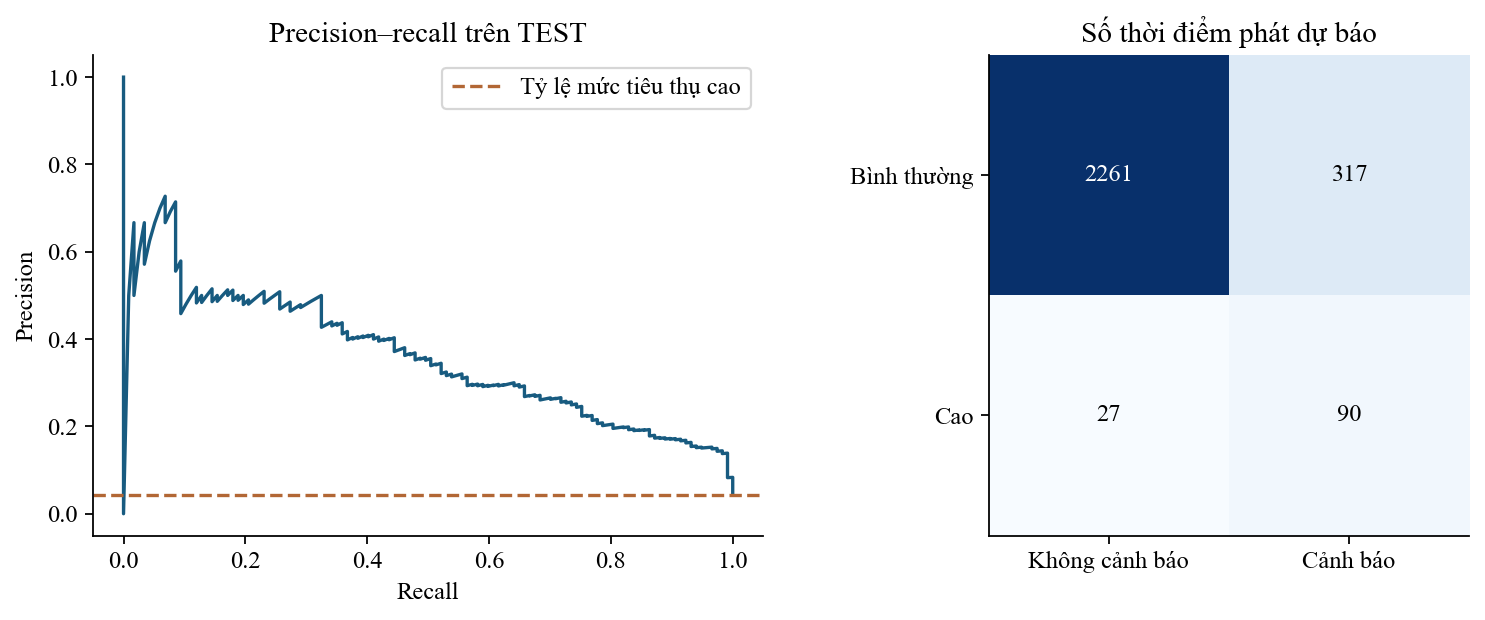

In [3]:
display(Image(filename=str(RELEASE / "figures/05_intervals.png")))
display(Image(filename=str(RELEASE / "figures/06_horizons.png")))
display(Image(filename=str(RELEASE / "figures/07_alerts.png")))


## 4.3 Ý nghĩa phân tích nhóm tiêu thụ cao
Ngưỡng lấy từ TRAIN. Coverage toàn bộ có thể che khuất độ tin cậy kém ở nhóm cao. Precision trả lời tỷ lệ cảnh báo đúng trong các lần đã cảnh báo, recall trả lời tỷ lệ phát hiện trong các mốc thật sự cao.

## 4.4 Phân tích các trường hợp khó
Kiểm tra nhóm tiêu thụ cao và các thời điểm có sai số lớn nhất.

,group,rows,mae_hour_kWh,coverage
0,All,2695,0.150373,0.784787
1,Normal,2578,0.106097,0.797130
2,High,117,1.125947,0.512821


,timestamp,forecast_end,actual_10m_kWh,actual_20m_kWh,actual_30m_kWh,actual_40m_kWh,actual_50m_kWh,actual_60m_kWh,predicted_10m_kWh,predicted_20m_kWh,...,predicted_60m_kWh,actual_hour_kWh,predicted_hour_kWh,p10_hour_kWh,p50_hour_kWh,p90_hour_kWh,lower_hour_kWh,upper_hour_kWh,hour,absolute_error_kWh
0,2016-05-26 16:20:00,2016-05-26 17:20:00,0.71,0.85,0.47,0.36,0.62,0.60,0.230669,0.160210,...,0.134631,3.61,0.952579,0.624263,1.191431,2.067409,0.592415,2.099257,16,2.657421
1,2016-05-26 16:00:00,2016-05-26 17:00:00,0.39,0.42,0.71,0.85,0.47,0.36,0.122821,0.115728,...,0.116712,3.20,0.712884,0.556273,0.833521,1.491143,0.524425,1.522991,16,2.487116
2,2016-05-26 15:50:00,2016-05-26 16:50:00,0.13,0.39,0.42,0.71,0.85,0.47,0.072533,0.071908,...,0.098768,2.97,0.487670,0.422310,0.568681,1.151081,0.390462,1.182929,15,2.482330
3,2016-05-26 16:10:00,2016-05-26 17:10:00,0.42,0.71,0.85,0.47,0.36,0.62,0.255731,0.176400,...,0.134119,3.43,0.965506,0.594989,1.049440,1.960712,0.563141,1.992560,16,2.464494
4,2016-05-26 15:40:00,2016-05-26 16:40:00,0.07,0.13,0.39,0.42,0.71,0.85,0.067978,0.073025,...,0.092838,2.57,0.476083,0.406391,0.553618,1.128915,0.374543,1.160762,15,2.093917


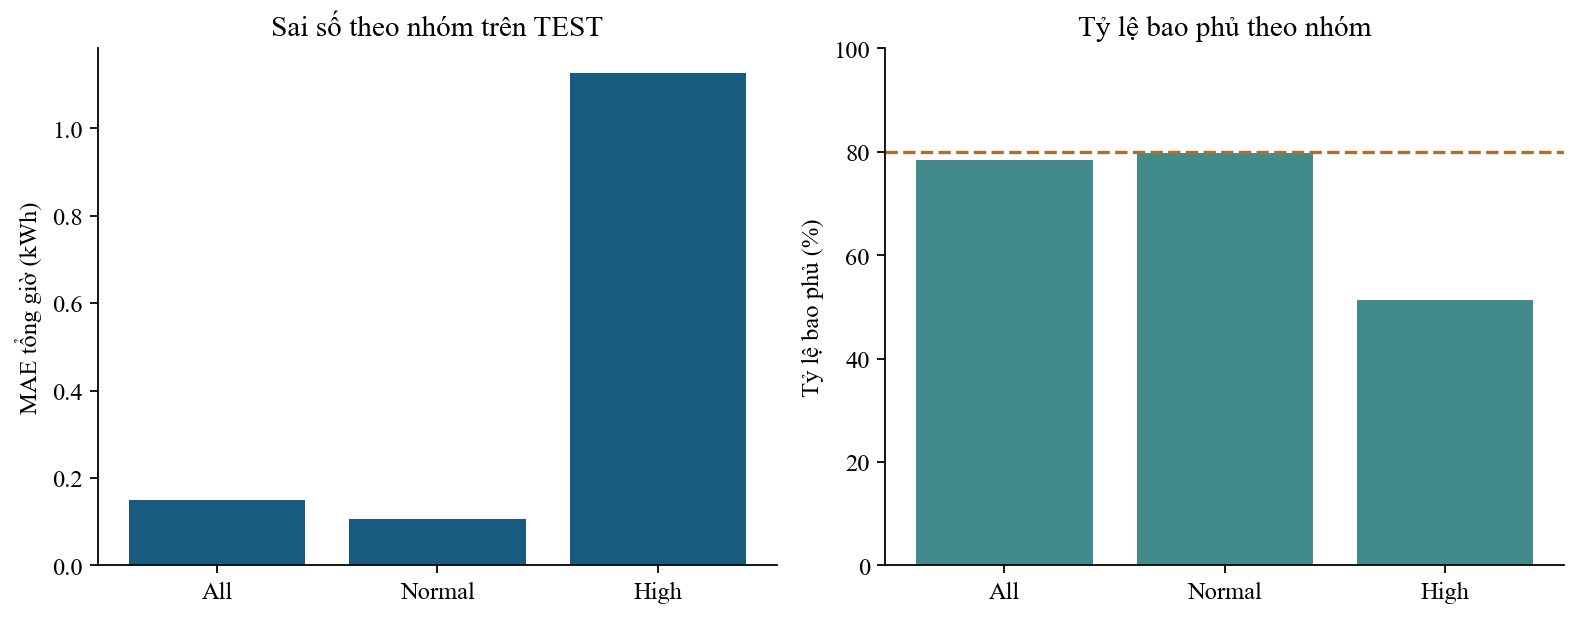

In [4]:
display(pd.read_csv(RELEASE / "conditional_errors.csv"))
display(pd.read_csv(RELEASE / "largest_errors.csv").head(5))
display(Image(filename=str(RELEASE / "figures/08_high_load.png")))


## 4.5 Kiểm chứng độc lập
Kiểm mã băm, toàn bộ nhãn, chỉ số và suy luận từ lịch sử đã quan sát.

In [5]:
from src.appliances.verification import verify

verification = verify()
display(pd.Series(verification))
assert verification["passed"]


passed                                                                    True
frozen_files_checked                                                        45
all_label_rows_reconciled    {'train': 11988, 'validation': 2010, 'calibrat...
causality_checks             [{'index': 1200, 'future_input_unchanged': Tru...
inference_origins_checked                                                  100
inference_p50_ms                                                      112.7625
inference_p95_ms                                                     196.91427
benchmark_scope              Features plus point and quantile inference, wa...
test_used_for_selection                                                  False
real_savings_measured                                                    False
human_group_acceptance                                                 pending
dtype: object

## 4.6 Giá trị ứng dụng và giới hạn
Kết quả đo khả năng cung cấp thông tin trước. Dataset chưa có hành động điều khiển, giá điện hoặc lượng tiết kiệm sau can thiệp để đo ROI thực tế.